# EDA 10 · Predicting per billing cycle: as-of = expiry − k

**Question.** Notebook 09 fixed the F1 ceiling at ~0.58. Most of the missed churners pay by auto-renew, and 47 % of
auto-renew churners cancel **after** the 2017-01-31 cutoff but **before** their expiry. A single calendar cutoff
cannot see that. If each customer is scored **k days before their own expiry**, how much better is the
prediction, and what is the trade-off between lead time (k) and precision?

**Setting.**
- **Anchor.** The expiry known at the reference date (2017-01-31 for February, 2017-02-28 for March), restricted to
  customers whose anchor falls inside the label month (`days_to_expire` 1–28 in February, 1–31 in March). They are
  the customers the label is defined for: 89.6 % of the February cohort. The rest (lapsed, paid through March or
  later, no transactions) keep the calendar cutoff and are out of scope here.
- **As-of.** `as_of = anchor − k` per customer, with k ∈ {28, 14, 7, 3, 1}. Every feature uses only records dated
  `<= as_of`. The listening window is the 90 days ending at `as_of`. Nothing from the expiry day onwards is used.
- **Eligibility, without look-ahead.** When `as_of` is before the reference date, the anchor itself comes from the
  future, so the customer is kept only if the expiry **known at `as_of`** already equals the anchor (the cycle being
  predicted had already started). When `as_of` is on or after the reference date, the anchor is known and every
  customer is kept. Whatever happened in between (a cancellation, an early renewal) is legitimate information.
- **Baseline ("calendar").** The same 20 features at the fixed reference date for the same customers. That is the
  w1 setting, where the lead time is a mix of 1–28 days.
- **Features.** The 20 features of notebook 08/09, with one change: `expiry_month` is replaced by the numeric
  `days_to_expire` at `as_of`, since every customer here expires in the label month.
- **Protocol.** Same as notebook 09: the same XGBoost settings, train on `fit`, early stopping on `stop`, F1
  threshold chosen on `tune`, evaluation on `tune` and on March. March is used to report, not to choose anything.

In [1]:
import sys
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, roc_auc_score
from xgboost import XGBClassifier

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

pd.options.display.float_format = "{:,.4f}".format
FEB_REF, MAR_REF = date(2017, 1, 31), date(2017, 2, 28)
KS = [28, 14, 7, 3, 1]
SCENARIOS = ["calendar"] + [f"k={k}" for k in KS]
cohort = C.load_cohort()
mar_cohort = pl.read_parquet(C.PARQUET_DIR / "train_v2.parquet", columns=["msno", "is_churn"]).with_columns(
    split=pl.lit("march"))

## 1. Population: customers whose anchor expiry is in the label month

In [2]:
def anchors(users, ref, max_days):
    # expiry known at the reference date; in scope when it falls inside the label month
    C.set_cutoff(ref)
    st = C.subscription_state(C.clean_transactions(users), users)
    C.set_cutoff(FEB_REF)
    return st.select("msno", anchor=pl.col("last_expire"), dte_ref=pl.col("days_to_expire"))

pop = {}
rows = []
for name, users, ref, max_days in (("February", cohort, FEB_REF, 28), ("March", mar_cohort, MAR_REF, 31)):
    a = users.join(anchors(users.select("msno", "is_churn"), ref, max_days), on="msno", how="left")
    a = a.with_columns(in_scope=pl.col("dte_ref").is_between(1, max_days).fill_null(False))
    for scope, g in a.group_by("in_scope"):
        rows.append({"cohort": name, "in scope": scope[0], "customers": g.height, "share": g.height / a.height,
                     "churn rate": g["is_churn"].mean()})
    pop[name] = a.filter("in_scope").select("msno", "is_churn", "anchor", "dte_ref")
pd.DataFrame(rows).sort_values(["cohort", "in scope"])

,cohort,in scope,customers,share,churn rate
0,February,False,109300,0.1101,0.1310
1,February,True,883631,0.8899,0.0556
2,March,False,105167,0.1083,0.2302
3,March,True,865793,0.8917,0.0729


Customers in scope churn **less** than the cohort as a whole, because the lapsed and long-prepaid groups are
excluded and their churn rates are extreme (nb 03). All the comparisons below are made inside this population, and
the calendar baseline is evaluated on exactly the same customers.

## 2. Raw data, loaded once

Transactions up to the last possible `as_of`, and cleaned daily logs covering every 90-day window. To fit in memory, `msno` is replaced by an integer id (`uid`) in both tables; the helpers of `_common` only join on the key, so they work unchanged with `msno = uid`.

In [3]:
import gc

def to_uid(df, ids):
    # replace the string msno by the integer id (column keeps the name `msno`)
    return df.join(ids, on="msno", how="inner").drop("msno").rename({"uid": "msno"})

raw, ids = {}, {}
for name, ref in (("February", FEB_REF), ("March", MAR_REF)):
    p = pop[name]
    ids[name] = p.select("msno").with_row_index("uid")
    last_asof = p["anchor"].max() - timedelta(days=1)
    first_asof = min(p["anchor"].min() - timedelta(days=max(KS)), ref)
    C.set_cutoff(last_asof)
    txn = to_uid(C.clean_transactions(p.select("msno")), ids[name])
    C.set_cutoff(FEB_REF)
    days = to_uid(C.daily_logs(p.select("msno"), first_asof - timedelta(days=C.WINDOW_DAYS - 1), last_asof), ids[name])
    raw[name] = (txn, days)
    gc.collect()
    print(f"{name}: as_of from {first_asof} to {last_asof} | {txn.height:,} transactions | {days.height:,} log days "
          f"| {(txn.estimated_size() + days.estimated_size()) / 1e9:.1f} GB")

February: as_of from 2017-01-04 to 2017-02-27 | 13,985,652 transactions | 53,067,001 log days | 1.2 GB


March: as_of from 2017-02-01 to 2017-03-30 | 14,215,597 transactions | 53,651,757 log days | 1.2 GB


## 3. Features at a per-customer as-of

In [4]:
# payment methods kept as their own level: learned on fit only (same rule as notebook 09)
fit_users = cohort.filter(pl.col("split") == "fit").select("msno", "is_churn")
C.set_cutoff(FEB_REF)
fit_state = C.subscription_state(C.clean_transactions(fit_users), fit_users)
counts = fit_state.group_by("last_payment_method_id").len()
KEEP_METHODS = counts.filter((pl.col("len") >= 1000) & pl.col("last_payment_method_id").is_not_null())["last_payment_method_id"].to_list()

CAT = ["state", "plan_band", "price_level", "price_type", "pm_group", "via", "profile_state", "age_band"]
NUM = ["days_to_expire", "payer_days", "n_payments", "n_lapses", "total_lapse_days", "has_logs",
       "days_since_last_log", "longest_gap", "active_days_30", "secs_30", "bd", "tenure_days"]
FEATURES = CAT + NUM

# E3c (notebook 11): features that let the model learn the KKBox label rule. A payment counts as renewal
# only when it is dated in [expiry, expiry + 30]; a payment made before the expiry does not.
KKBOX = ["paid_ahead", "days_early", "ahead_plan_days", "ahead_auto", "n_ahead_payments", "ahead_extension"]
KEEP_COLS = ["msno", "is_churn", "as_of", "eligible"] + FEATURES + KKBOX

def kkbox_block(txn, users_u):
    # payments dated <= as_of whose expiry goes past the anchor (already filtered to as_of by the caller)
    ahead = (txn.filter(pl.col("is_cancel") == 0).join(users_u.select("msno", "anchor"), on="msno")
             .filter(pl.col("ed") > pl.col("anchor")).sort("td", "ed", "_ord")
             .group_by("msno").agg(ahead_date=pl.col("td").first(),
                                   ahead_plan_days=pl.col("payment_plan_days").first().cast(pl.Float64),
                                   ahead_auto=pl.col("is_auto_renew").first().cast(pl.Float64),
                                   n_ahead_payments=pl.len(), ahead_max_expire=pl.col("ed").max()))
    return (users_u.select("msno", "anchor").join(ahead, on="msno", how="left")
            .select("msno",
                    paid_ahead=pl.col("ahead_date").is_not_null().cast(pl.Int8),
                    days_early=(pl.col("anchor") - pl.col("ahead_date")).dt.total_days().cast(pl.Float64),
                    ahead_plan_days="ahead_plan_days", ahead_auto="ahead_auto",
                    n_ahead_payments=pl.col("n_ahead_payments").fill_null(0),
                    ahead_extension=(pl.col("ahead_max_expire") - pl.col("anchor")).dt.total_days().cast(pl.Float64)))

def features_at(name, scenario):
    # 20 features for every in-scope customer of `name` at the as-of of `scenario`; adds `eligible`
    p, ref = pop[name], (FEB_REF if name == "February" else MAR_REF)
    txn_all, days = raw[name]
    if scenario == "calendar":
        as_of = pl.lit(ref)
    else:
        as_of = pl.col("anchor") - pl.duration(days=int(scenario.split("=")[1]))
    users = p.with_columns(as_of=as_of)               # string msno: members table
    users_u = to_uid(users, ids[name])                # integer msno: transactions and logs
    txn = C.filter_as_of(txn_all, users_u)
    st = C.state_block(C.subscription_state(txn, users_u), keep_methods=KEEP_METHODS)
    df = (st.join(C.history_block(txn, users_u), on="msno")
            .join(C.listening_block(users_u, days=days), on="msno")
            .join(kkbox_block(txn, users_u), on="msno")
            .with_columns(payer_days=pl.col("payer_days").clip(upper_bound=730),
                          # anchor known at as_of: either as_of is past the reference date, or the
                          # expiry known at as_of is already the anchor
                          eligible=(pl.col("as_of") >= pl.lit(ref)) | (pl.col("last_expire") == pl.col("anchor")).fill_null(False))
            .rename({"msno": "uid"}).join(ids[name], on="uid").drop("uid")      # back to the string msno
            .join(C.member_block(users), on="msno"))
    return df.select(KEEP_COLS)

tables = {(n, s): features_at(n, s) for n in ("February", "March") for s in SCENARIOS}
cov = pd.DataFrame([{"cohort": n, "scenario": s, "eligible": t["eligible"].mean(),
                     "churn rate (eligible)": t.filter("eligible")["is_churn"].mean(),
                     "churn rate (not eligible)": t.filter(~pl.col("eligible"))["is_churn"].mean()}
                    for (n, s), t in tables.items()])
cov.pivot(index="scenario", columns="cohort").loc[SCENARIOS]

eligible        churn rate (eligible)         \
cohort   February  March              February  March   
scenario                                                
calendar   1.0000 1.0000                0.0556 0.0729   
k=28       0.9990 0.8504                0.0549 0.0786   
k=14       0.9990 0.9995                0.0549 0.0726   
k=7        0.9998 0.9996                0.0556 0.0727   
k=3        0.9999 0.9998                0.0556 0.0728   
k=1        1.0000 1.0000                0.0556 0.0729   

         churn rate (not eligible)         
cohort                    February  March  
scenario                                   
calendar                       NaN    NaN  
k=28                        0.7968 0.0404  
k=14                        0.8146 0.6548  
k=7                         0.4730 0.6420  
k=3                         0.4651 0.4866  
k=1                            NaN    NaN

In [5]:
# sanity: the calendar scenario reproduces the global-cutoff helpers of notebooks 03-09 on a sample
sample = pop["February"].sample(20_000, seed=C.SEED).select("msno", "is_churn")
C.set_cutoff(FEB_REF)
t_glob = C.clean_transactions(sample)
ref_tab = (C.state_block(C.subscription_state(t_glob, sample), keep_methods=KEEP_METHODS)
           .join(C.history_block(t_glob, sample), on="msno").join(C.listening_block(sample), on="msno")
           .join(C.member_block(sample), on="msno")
           .with_columns(payer_days=pl.col("payer_days").clip(upper_bound=730)).sort("msno"))
cal = tables[("February", "calendar")].join(sample.select("msno"), on="msno", how="semi").sort("msno")
for c in FEATURES:
    a, b = ref_tab[c].to_numpy(), cal[c].to_numpy()
    assert np.array_equal(a, b) or np.allclose(a.astype(float), b.astype(float), equal_nan=True, rtol=1e-5), c
print("calendar scenario == global cutoff on", sample.height, "customers")

calendar scenario == global cutoff on 20000 customers


**Leakage check.** For every scenario the maximum transaction date and the maximum log date used must be strictly
before the customer's anchor.

In [6]:
chk = []
for name in ("February", "March"):
    txn_all, days = raw[name]
    for s in SCENARIOS[1:]:
        k = int(s.split("=")[1])
        u = to_uid(pop[name].with_columns(as_of=pl.col("anchor") - pl.duration(days=k)), ids[name])
        t = C.filter_as_of(txn_all, u).join(u.select("msno", "anchor"), on="msno")
        d = days.join(u.select("msno", "as_of", "anchor"), on="msno").filter(pl.col("date") <= pl.col("as_of"))
        chk.append({"cohort": name, "scenario": s,
                    "max txn date - anchor (days)": (t["td"] - t["anchor"]).dt.total_days().max(),
                    "max log date - anchor (days)": (d["date"] - d["anchor"]).dt.total_days().max()})
chk = pd.DataFrame(chk)
assert (chk.iloc[:, 2:] < 0).all().all()
del raw, t, d; gc.collect()
chk

,cohort,scenario,max txn date - anchor (days),max log date - anchor (days)
0,February,k=28,-28,-28
1,February,k=14,-14,-14
2,February,k=7,-7,-7
3,February,k=3,-3,-3
4,February,k=1,-1,-1
5,March,k=28,-28,-28
6,March,k=14,-14,-14
7,March,k=7,-7,-7
8,March,k=3,-3,-3
9,March,k=1,-1,-1


## 4. One model per scenario

In [7]:
LEVELS = {c: sorted(v for v in pl.concat([tables[("February", s)][c] for s in SCENARIOS]).unique().to_list()
                    if v is not None) for c in CAT}

def to_X(df):
    p = df.select(FEATURES).to_pandas()
    for c in CAT:
        codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)
        codes[codes < 0] = np.nan
        p[c] = codes
    return p.astype(float)

PARAMS = dict(n_estimators=4000, learning_rate=0.05, max_depth=6, min_child_weight=5, subsample=0.8,
              colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist", eval_metric="aucpr",
              early_stopping_rounds=150, enable_categorical=True, max_cat_to_onehot=1,
              n_jobs=16, random_state=C.SEED)
FT = ["c" if c in CAT else "q" for c in FEATURES]

split_of = cohort.select("msno", "split")
scores = []          # msno, cohort, part, scenario, eligible, is_churn, p
thresholds, models = {}, {}
for s in SCENARIOS:
    feb = tables[("February", s)].join(split_of, on="msno")
    mar = tables[("March", s)].with_columns(split=pl.lit("march"))
    tr, st_ = feb.filter(pl.col("eligible") & (pl.col("split") == "fit")), feb.filter(pl.col("eligible") & (pl.col("split") == "stop"))
    m = XGBClassifier(**PARAMS, feature_types=FT)
    m.fit(to_X(tr), tr["is_churn"].to_numpy(), eval_set=[(to_X(st_), st_["is_churn"].to_numpy())], verbose=False)
    models[s] = m
    tune = feb.filter(pl.col("split") == "tune")
    for part, d in (("tune", tune), ("march", mar)):
        scores.append(d.select("msno", "eligible", "is_churn", "state", "as_of", "days_to_expire")
                      .with_columns(part=pl.lit(part), scenario=pl.lit(s), p=pl.Series(m.predict_proba(to_X(d))[:, 1])))
    te = tune.filter("eligible")
    prec, rec, thr = precision_recall_curve(te["is_churn"].to_numpy(), m.predict_proba(to_X(te))[:, 1])
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    thresholds[s] = thr[np.argmax(f1[:-1])]
    print(f"{s:9s} trained on {tr.height:,} | best iteration {m.best_iteration} | threshold {thresholds[s]:.3f}")
scores = pl.concat(scores)

/tmp/ipykernel_4/1286032209.py:7: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)


calendar  trained on 662,730 | best iteration 195 | threshold 0.230


/tmp/ipykernel_4/1286032209.py:7: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)


k=28      trained on 662,047 | best iteration 282 | threshold 0.222


/tmp/ipykernel_4/1286032209.py:7: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)


k=14      trained on 662,099 | best iteration 227 | threshold 0.241


... (2 outputs left out)

/tmp/ipykernel_4/1286032209.py:7: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)


k=3       trained on 662,634 | best iteration 244 | threshold 0.295


/tmp/ipykernel_4/1286032209.py:7: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)


k=1       trained on 662,730 | best iteration 394 | threshold 0.330


## 5. Results

### 5.1 Each scenario on its own eligible customers

In [8]:
def metrics(d, s):
    y, p = d["is_churn"].to_numpy(), d["p"].to_numpy()
    yhat = (p >= thresholds[s]).astype(int)
    tp = (yhat & y).sum()
    return {"n": len(y), "churn rate": y.mean(), "roc_auc": roc_auc_score(y, p),
            "avg_precision": average_precision_score(y, p), "precision": tp / max(yhat.sum(), 1),
            "recall": tp / y.sum(), "f1": f1_score(y, yhat)}

own = pd.DataFrame([{"evaluated on": part, "scenario": s, **metrics(g, s)}
                    for (part, s), g in scores.filter("eligible").group_by("part", "scenario")])
own["scenario"] = pd.Categorical(own["scenario"], SCENARIOS, ordered=True)
own.sort_values(["evaluated on", "scenario"]).set_index(["evaluated on", "scenario"])

n  churn rate  roc_auc  avg_precision  precision  \
evaluated on scenario                                                          
march        calendar  865793      0.0729   0.8837         0.5408     0.5723   
             k=28      736290      0.0786   0.8919         0.5487     0.5637   
             k=14      865373      0.0726   0.8989         0.5773     0.6010   
             k=7       865441      0.0727   0.9105         0.6180     0.6414   
             k=3       865606      0.0728   0.9207         0.6502     0.6778   
             k=1       865793      0.0729   0.9286         0.6816     0.7085   
tune         calendar  110359      0.0552   0.8861         0.4658     0.4422   
             k=28      110238      0.0544   0.8800         0.4272     0.4253   
             k=14      110250      0.0545   0.8970         0.4967     0.4557   
             k=7       110341      0.0552   0.9142         0.5686     0.5035   
             k=3       110346      0.0552   0.9279         0.6310     0.5634   
             k=1       110359      0.0552   0.9392         0.6924     0.6373   

                       recall     f1  
evaluated on scenario                 
march        calendar  0.5416 0.5566  
             k=28      0.5678 0.5658  
             k=14      0.5559 0.5776  
             k=7       0.5560 0.5956  
             k=3       0.5245 0.5914  
             k=1       0.5054 0.5900  
tune         calendar  0.5438 0.4878  
             k=28      0.5297 0.4718  
             k=14      0.5571 0.5013  
             k=7       0.5846 0.5410  
             k=3       0.5876 0.5753  
             k=1       0.6134 0.6251

### 5.2 Same customers for every scenario

The eligible population changes with k, so the fair comparison uses the customers eligible in **every** scenario.
Each model keeps the threshold it chose on its own eligible `tune` rows.

In [9]:
common_ids = {part: (scores.filter(pl.col("part") == part).group_by("msno").agg(pl.col("eligible").all())
                     .filter("eligible").select("msno")) for part in ("tune", "march")}
common = pl.concat([scores.filter(pl.col("part") == part).join(ids, on="msno", how="semi")
                    for part, ids in common_ids.items()])
res = pd.DataFrame([{"evaluated on": part, "scenario": s, **metrics(g, s)}
                    for (part, s), g in common.group_by("part", "scenario")])
res["scenario"] = pd.Categorical(res["scenario"], SCENARIOS, ordered=True)
res = res.sort_values(["evaluated on", "scenario"]).set_index(["evaluated on", "scenario"])
res

n  churn rate  roc_auc  avg_precision  precision  \
evaluated on scenario                                                          
march        calendar  736290      0.0786   0.8898         0.5541     0.5702   
             k=28      736290      0.0786   0.8919         0.5487     0.5637   
             k=14      736290      0.0786   0.9061         0.5939     0.6001   
             k=7       736290      0.0786   0.9168         0.6314     0.6396   
             k=3       736290      0.0786   0.9265         0.6596     0.6741   
             k=1       736290      0.0786   0.9342         0.6908     0.7015   
tune         calendar  110238      0.0544   0.8845         0.4518     0.4364   
             k=28      110238      0.0544   0.8800         0.4272     0.4253   
             k=14      110238      0.0544   0.8970         0.4966     0.4557   
             k=7       110238      0.0544   0.9131         0.5591     0.4981   
             k=3       110238      0.0544   0.9270         0.6232     0.5585   
             k=1       110238      0.0544   0.9384         0.6860     0.6331   

                       recall     f1  
evaluated on scenario                 
march        calendar  0.5629 0.5665  
             k=28      0.5678 0.5658  
             k=14      0.5781 0.5889  
             k=7       0.5721 0.6040  
             k=3       0.5344 0.5962  
             k=1       0.5129 0.5926  
tune         calendar  0.5371 0.4815  
             k=28      0.5297 0.4718  
             k=14      0.5569 0.5012  
             k=7       0.5789 0.5355  
             k=3       0.5819 0.5699  
             k=1       0.6079 0.6202

In [10]:
rng = np.random.default_rng(C.SEED)
def paired_bootstrap(part, s, n=200):
    a = common.filter((pl.col("part") == part) & (pl.col("scenario") == "calendar")).sort("msno")
    b = common.filter((pl.col("part") == part) & (pl.col("scenario") == s)).sort("msno")
    y, pa, pb = a["is_churn"].to_numpy(), a["p"].to_numpy(), b["p"].to_numpy()
    d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        d.append(average_precision_score(y[i], pb[i]) - average_precision_score(y[i], pa[i]))
    return np.mean(d), np.percentile(d, 2.5), np.percentile(d, 97.5)

boot = pd.DataFrame([{"evaluated on": part, "scenario": s, **dict(zip(["d_ap mean", "ci_95_low", "ci_95_high"],
                      paired_bootstrap(part, s)))} for part in ("tune", "march") for s in SCENARIOS[1:]])
boot.set_index(["evaluated on", "scenario"])

d_ap mean  ci_95_low  ci_95_high
evaluated on scenario                                  
tune         k=28        -0.0244    -0.0307     -0.0190
             k=14         0.0446     0.0376      0.0518
             k=7          0.1073     0.0985      0.1164
             k=3          0.1711     0.1613      0.1813
             k=1          0.2344     0.2231      0.2471
march        k=28        -0.0053    -0.0072     -0.0038
             k=14         0.0397     0.0374      0.0420
             k=7          0.0773     0.0748      0.0799
             k=3          0.1056     0.1026      0.1084
             k=1          0.1367     0.1333      0.1398

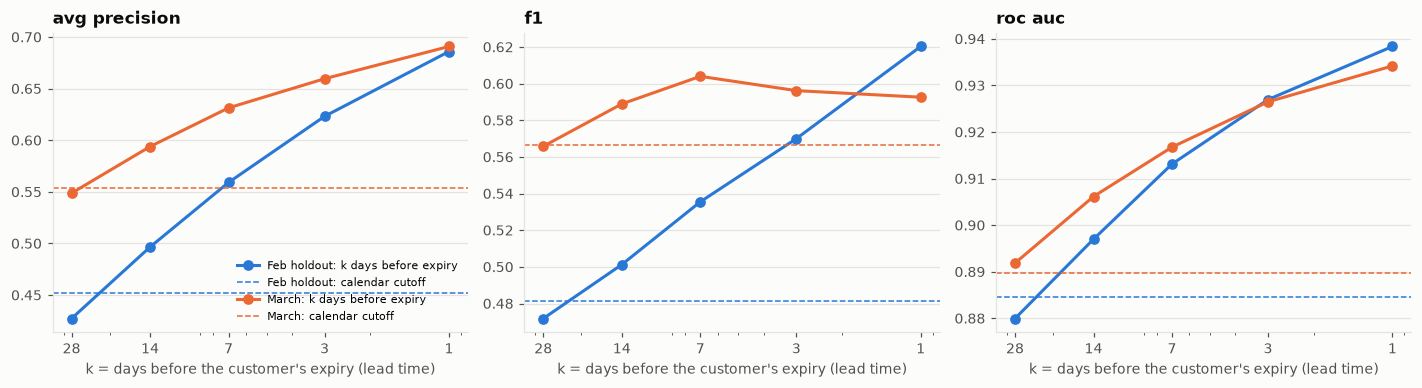

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, metric in zip(axes, ["avg_precision", "f1", "roc_auc"]):
    for part, color in (("tune", C.COLORS["stay"]), ("march", C.COLORS["churn"])):
        r = res.loc[part]
        ax.plot(KS, [r.loc[f"k={k}", metric] for k in KS], marker="o", color=color, linewidth=2,
                label=f"{'Feb holdout' if part == 'tune' else 'March'}: k days before expiry")
        ax.axhline(r.loc["calendar", metric], color=color, linestyle="--", linewidth=1,
                   label=f"{'Feb holdout' if part == 'tune' else 'March'}: calendar cutoff")
    ax.set_xscale("log"); ax.set_xticks(KS, [str(k) for k in KS]); ax.invert_xaxis()
    ax.set_xlabel("k = days before the customer's expiry (lead time)")
    ax.set_title(metric.replace("_", " "), loc="left")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout(); C.save_fig(fig, "10_k_curve"); plt.show()

### 5.3 Where the gain comes from

In [12]:
# state at as_of of the churners, by scenario (common customers, Feb holdout + March)
churners = common.filter(pl.col("is_churn") == 1)
state_mix = (churners.group_by("part", "scenario", "state").len()
             .with_columns(share=pl.col("len") / pl.col("len").sum().over("part", "scenario"))
             .to_pandas().pivot_table(index=["part", "scenario"], columns="state", values="share").fillna(0))
state_mix.loc[[(p, s) for p in ("tune", "march") for s in SCENARIOS]][C.STATE_ORDER[:-1]]

state           auto-renew  manual  cancel + payment  cancel
part  scenario                                              
tune  calendar      0.3369  0.6186            0.0070  0.0375
      k=28          0.3573  0.6187            0.0070  0.0170
      k=14          0.3051  0.6187            0.0073  0.0688
      k=7           0.2631  0.6192            0.0073  0.1103
      k=3           0.2250  0.6201            0.0075  0.1475
      k=1           0.1976  0.6204            0.0077  0.1743
march calendar      0.2714  0.6952            0.0041  0.0293
      k=28          0.2801  0.6954            0.0041  0.0204
      k=14          0.2438  0.6958            0.0043  0.0562
      k=7           0.2136  0.6961            0.0044  0.0859
      k=3           0.1891  0.6963            0.0044  0.1102
      k=1           0.1714  0.6940            0.0040  0.1306

In [13]:
# recall at each model's threshold, split by the state the customer had at the reference date (calendar view)
ref_state = common.filter(pl.col("scenario") == "calendar").select("msno", "part", ref_state="state")
rec = (common.join(ref_state, on=["msno", "part"])
       .with_columns(hit=(pl.col("p") >= pl.col("scenario").replace_strict(thresholds)).cast(pl.Int8))
       .group_by("part", "scenario", "ref_state")
       .agg(churners=(pl.col("is_churn") == 1).sum(),
            recall=pl.col("hit").filter(pl.col("is_churn") == 1).mean(),
            precision=pl.col("is_churn").filter(pl.col("hit") == 1).mean())
       .to_pandas())
rec["scenario"] = pd.Categorical(rec["scenario"], SCENARIOS, ordered=True)
rec[rec["ref_state"].isin(["auto-renew", "manual"])].pivot_table(
    index=["part", "scenario"], columns="ref_state", values=["recall", "precision"], observed=True)

precision            recall       
ref_state      auto-renew manual auto-renew manual
part  scenario                                    
march calendar     0.4149 0.5655     0.0074 0.7627
      k=28         0.4386 0.5609     0.0202 0.7732
      k=14         0.8661 0.5841     0.1202 0.7447
      k=7          0.8966 0.6134     0.2236 0.6942
      k=3          0.8983 0.6381     0.3081 0.6074
      k=1          0.8946 0.6585     0.3783 0.5503
tune  calendar     0.4717 0.4244     0.0618 0.7670
      k=28         0.4150 0.4184     0.0628 0.7734
      k=14         0.6890 0.4290     0.1677 0.7497
      k=7          0.7784 0.4551     0.2779 0.7220
      k=3          0.8181 0.5030     0.3714 0.6756
      k=1          0.8289 0.5786     0.4431 0.6781

In [14]:
imp = pd.DataFrame({s: pd.Series(models[s].get_booster().get_score(importance_type="total_gain")) for s in SCENARIOS})
imp.index = [FEATURES[int(k[1:])] if k.startswith("f") and k[1:].isdigit() else k for k in imp.index]
(imp / imp.sum()).sort_values("calendar", ascending=False).head(10)

,calendar,k=28,k=14,k=7,k=3,k=1
state,0.4491,0.4283,0.4623,0.4698,0.4795,0.4645
pm_group,0.2177,0.2334,0.2045,0.1883,0.1699,0.1547
payer_days,0.0485,0.0525,0.0434,0.0374,0.0311,0.0209
longest_gap,0.0371,0.0314,0.0316,0.0380,0.0386,0.0451
secs_30,0.0367,0.0375,0.0201,0.0178,0.0144,0.0141
price_level,0.0362,0.0392,0.0281,0.0221,0.0204,0.0140
active_days_30,0.0305,0.0305,0.0318,0.0238,0.0214,0.0221
n_lapses,0.0268,0.0243,0.0257,0.0225,0.0150,0.0074
days_since_last_log,0.0206,0.0186,0.0393,0.0503,0.0541,0.0525
n_payments,0.0190,0.0262,0.0209,0.0202,0.0188,0.0283


## 6. E3c · Features for the KKBox label rule

Notebook 11 showed that `is_churn` = "no payment **dated** in [expiry, expiry + 30]": a payment made before the
expiry does not count as a renewal. About a quarter of the manual churners are customers who paid ahead. Six
features, all dated `<= as_of`, describe that early payment:

| feature | meaning |
|---|---|
| `paid_ahead` | a payment dated before `as_of` whose expiry goes past the anchor |
| `days_early` | anchor − date of that payment |
| `ahead_plan_days` | plan length of that payment |
| `ahead_auto` | whether that payment is an auto-renew charge |
| `n_ahead_payments` | number of such payments |
| `ahead_extension` | latest expiry − anchor (> 30: the next payment will fall outside the label window) |

They are all zero or null in the calendar scenario, whose `as_of` is the reference date. Variant **+kkbox** =
the 20 features + these 6, with the same XGBoost, split and threshold rule. The comparison uses the same common
customers as section 5.2.

In [15]:
FEATURES_PLUS = FEATURES + KKBOX
FT_PLUS = FT + ["q"] * len(KKBOX)

def to_X_plus(df):
    X = to_X(df)
    for c in KKBOX:
        X[c] = df[c].cast(pl.Float64).to_numpy()
    return X

scores_plus, thresholds_plus, models_plus = [], {}, {}
for s in SCENARIOS:
    feb = tables[("February", s)].join(split_of, on="msno")
    mar = tables[("March", s)].with_columns(split=pl.lit("march"))
    tr, st_ = feb.filter(pl.col("eligible") & (pl.col("split") == "fit")), feb.filter(pl.col("eligible") & (pl.col("split") == "stop"))
    m = XGBClassifier(**PARAMS, feature_types=FT_PLUS)
    m.fit(to_X_plus(tr), tr["is_churn"].to_numpy(), eval_set=[(to_X_plus(st_), st_["is_churn"].to_numpy())], verbose=False)
    models_plus[s] = m
    tune = feb.filter(pl.col("split") == "tune")
    for part, d in (("tune", tune), ("march", mar)):
        scores_plus.append(d.select("msno", "eligible", "is_churn", "state", "paid_ahead", "ahead_extension")
                           .with_columns(part=pl.lit(part), scenario=pl.lit(s), p=pl.Series(m.predict_proba(to_X_plus(d))[:, 1])))
    te = tune.filter("eligible")
    prec, rec, thr = precision_recall_curve(te["is_churn"].to_numpy(), m.predict_proba(to_X_plus(te))[:, 1])
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    thresholds_plus[s] = thr[np.argmax(f1[:-1])]
    print(f"{s:9s} +kkbox | best iteration {m.best_iteration} | threshold {thresholds_plus[s]:.3f}")
scores_plus = pl.concat(scores_plus)
common_plus = pl.concat([scores_plus.filter(pl.col("part") == part).join(ids_, on="msno", how="semi")
                         for part, ids_ in common_ids.items()])

/tmp/ipykernel_4/1286032209.py:7: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)


calendar  +kkbox | best iteration 202 | threshold 0.218


/tmp/ipykernel_4/1286032209.py:7: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)


k=28      +kkbox | best iteration 236 | threshold 0.225


/tmp/ipykernel_4/1286032209.py:7: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)


k=14      +kkbox | best iteration 325 | threshold 0.255


... (2 outputs left out)

/tmp/ipykernel_4/1286032209.py:7: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)


k=3       +kkbox | best iteration 238 | threshold 0.288


/tmp/ipykernel_4/1286032209.py:7: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)


k=1       +kkbox | best iteration 269 | threshold 0.343


In [16]:
def metrics_t(d, thr):
    y, p = d["is_churn"].to_numpy(), d["p"].to_numpy()
    yhat = (p >= thr).astype(int)
    tp = (yhat & y).sum()
    return {"avg_precision": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p),
            "precision": tp / max(yhat.sum(), 1), "recall": tp / y.sum(), "f1": f1_score(y, yhat)}

rows = []
for variant, sc, thr in (("base", common, thresholds), ("+kkbox", common_plus, thresholds_plus)):
    for (part, s), g in sc.group_by("part", "scenario"):
        rows.append({"evaluated on": part, "scenario": s, "variant": variant, **metrics_t(g, thr[s])})
cmp_ = pd.DataFrame(rows)
cmp_["scenario"] = pd.Categorical(cmp_["scenario"], SCENARIOS, ordered=True)
cmp_ = cmp_.pivot_table(index=["evaluated on", "scenario"], columns="variant", observed=True,
                        values=["avg_precision", "f1", "precision", "recall"])[
    [(m, v) for m in ("avg_precision", "f1", "precision", "recall") for v in ("base", "+kkbox")]]
cmp_

avg_precision            f1        precision         \
variant                        base +kkbox   base +kkbox      base +kkbox   
evaluated on scenario                                                       
march        calendar        0.5541 0.5541 0.5665 0.5676    0.5702 0.5610   
             k=28            0.5487 0.5487 0.5658 0.5657    0.5637 0.5661   
             k=14            0.5939 0.5939 0.5889 0.5861    0.6001 0.6139   
             k=7             0.6314 0.6311 0.6040 0.6054    0.6396 0.6351   
             k=3             0.6596 0.6598 0.5962 0.6012    0.6741 0.6694   
             k=1             0.6908 0.6916 0.5926 0.5856    0.7015 0.7096   
tune         calendar        0.4518 0.4522 0.4815 0.4813    0.4364 0.4297   
             k=28            0.4272 0.4271 0.4718 0.4709    0.4253 0.4267   
             k=14            0.4966 0.4978 0.5012 0.5034    0.4557 0.4674   
             k=7             0.5591 0.5579 0.5355 0.5352    0.4981 0.4931   
             k=3             0.6232 0.6225 0.5699 0.5683    0.5585 0.5497   
             k=1             0.6860 0.6862 0.6202 0.6189    0.6331 0.6450   

                      recall         
variant                 base +kkbox  
evaluated on scenario                
march        calendar 0.5629 0.5744  
             k=28     0.5678 0.5654  
             k=14     0.5781 0.5607  
             k=7      0.5721 0.5784  
             k=3      0.5344 0.5456  
             k=1      0.5129 0.4985  
tune         calendar 0.5371 0.5469  
             k=28     0.5297 0.5254  
             k=14     0.5569 0.5454  
             k=7      0.5789 0.5852  
             k=3      0.5819 0.5882  
             k=1      0.6079 0.5947

In [17]:
def paired_plus(part, s, n=200):
    a = common.filter((pl.col("part") == part) & (pl.col("scenario") == s)).sort("msno")
    b = common_plus.filter((pl.col("part") == part) & (pl.col("scenario") == s)).sort("msno")
    assert (a["msno"] == b["msno"]).all()
    y, pa, pb = a["is_churn"].to_numpy(), a["p"].to_numpy(), b["p"].to_numpy()
    d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        d.append(average_precision_score(y[i], pb[i]) - average_precision_score(y[i], pa[i]))
    return np.mean(d), np.percentile(d, 2.5), np.percentile(d, 97.5)

boot_plus = pd.DataFrame([{"evaluated on": part, "scenario": s, **dict(zip(["d_ap (+kkbox - base)", "ci_95_low", "ci_95_high"],
                           paired_plus(part, s)))} for part in ("tune", "march") for s in SCENARIOS[1:]])
boot_plus.set_index(["evaluated on", "scenario"])

d_ap (+kkbox - base)  ci_95_low  ci_95_high
evaluated on scenario                                             
tune         k=28                   -0.0001    -0.0017      0.0015
             k=14                    0.0012    -0.0001      0.0024
             k=7                    -0.0012    -0.0023     -0.0000
             k=3                    -0.0006    -0.0016      0.0004
             k=1                     0.0002    -0.0008      0.0013
march        k=28                   -0.0001    -0.0006      0.0004
             k=14                    0.0000    -0.0004      0.0005
             k=7                    -0.0002    -0.0006      0.0001
             k=3                     0.0002    -0.0001      0.0006
             k=1                     0.0008     0.0004      0.0012

### 6.1 Customers who paid ahead before `as_of`

In [18]:
pa = (common_plus.select("msno", "part", "scenario", "paid_ahead", "ahead_extension")
      .join(common.select("msno", "part", "scenario", p_base="p"), on=["msno", "part", "scenario"])
      .join(common_plus.select("msno", "part", "scenario", "is_churn", p_plus="p"), on=["msno", "part", "scenario"]))
rows = []
for (part, s), g in pa.filter(pl.col("paid_ahead") == 1).group_by("part", "scenario"):
    y = g["is_churn"].to_numpy()
    if y.sum() < 20 or y.sum() == len(y):
        continue
    rows.append({"evaluated on": part, "scenario": s, "paid ahead (share of customers)": g.height / pa.filter((pl.col("part") == part) & (pl.col("scenario") == s)).height,
                 "churn rate": y.mean(), "churners": int(y.sum()),
                 "AP base": average_precision_score(y, g["p_base"].to_numpy()),
                 "AP +kkbox": average_precision_score(y, g["p_plus"].to_numpy()),
                 "recall base": ((g["p_base"].to_numpy() >= thresholds[s]) & (y == 1)).sum() / y.sum(),
                 "recall +kkbox": ((g["p_plus"].to_numpy() >= thresholds_plus[s]) & (y == 1)).sum() / y.sum()})
sub = pd.DataFrame(rows)
sub["scenario"] = pd.Categorical(sub["scenario"], SCENARIOS, ordered=True)
sub.sort_values(["evaluated on", "scenario"]).set_index(["evaluated on", "scenario"])

paid ahead (share of customers)  churn rate  churners  \
evaluated on scenario                                                          
march        calendar                           0.0071      0.0403       211   
             k=28                               0.0074      0.0461       250   
             k=14                               0.0115      0.0704       594   
             k=7                                0.0191      0.1210      1701   
             k=3                                0.0498      0.1455      5338   
             k=1                                0.1406      0.1343     13901   
tune         calendar                           0.0072      0.0304        24   
             k=28                               0.0072      0.0304        24   
             k=14                               0.0098      0.0518        56   
             k=7                                0.0154      0.1105       188   
             k=3                                0.0384      0.1345       570   
             k=1                                0.1116      0.1006      1238   

                       AP base  AP +kkbox  recall base  recall +kkbox  
evaluated on scenario                                                  
march        calendar   0.6280     0.6212       0.5735         0.5735  
             k=28       0.6219     0.6228       0.5120         0.5120  
             k=14       0.7361     0.7376       0.6364         0.6246  
             k=7        0.8486     0.8456       0.7648         0.7625  
             k=3        0.8129     0.8144       0.7274         0.7332  
             k=1        0.7056     0.7068       0.6141         0.6128  
tune         calendar   0.6282     0.6167       0.5833         0.5833  
             k=28       0.6107     0.6157       0.5833         0.5833  
             k=14       0.7866     0.7830       0.7500         0.7500  
             k=7        0.9080     0.9043       0.8830         0.8830  
             k=3        0.8891     0.8858       0.8491         0.8509  
             k=1        0.8312     0.8335       0.7948         0.7908

In [19]:
# churn rate of early payers by how far the early payment extends the subscription (the KKBox window is 30 days)
ext = (pa.filter((pl.col("paid_ahead") == 1) & (pl.col("scenario") == "k=1"))
       .with_columns(extension=pl.when(pl.col("ahead_extension") <= 25).then(pl.lit("<= 25"))
                     .when(pl.col("ahead_extension") <= 30).then(pl.lit("26-30"))
                     .when(pl.col("ahead_extension") <= 35).then(pl.lit("31-35"))
                     .when(pl.col("ahead_extension") <= 90).then(pl.lit("36-90")).otherwise(pl.lit("91+"))))
ext.group_by("part", "extension").agg(n=pl.len(), churn=pl.col("is_churn").mean()).sort("part", "extension").to_pandas()

,part,extension,n,churn
0,march,26-30,11300,0.4234
1,march,31-35,80631,0.0549
2,march,36-90,1493,0.4963
3,march,91+,7144,0.5174
4,march,<= 25,2924,0.0872
5,tune,26-30,10546,0.0609
6,tune,31-35,16,0.0000
7,tune,36-90,259,0.4363
8,tune,91+,998,0.4679
9,tune,<= 25,488,0.0328


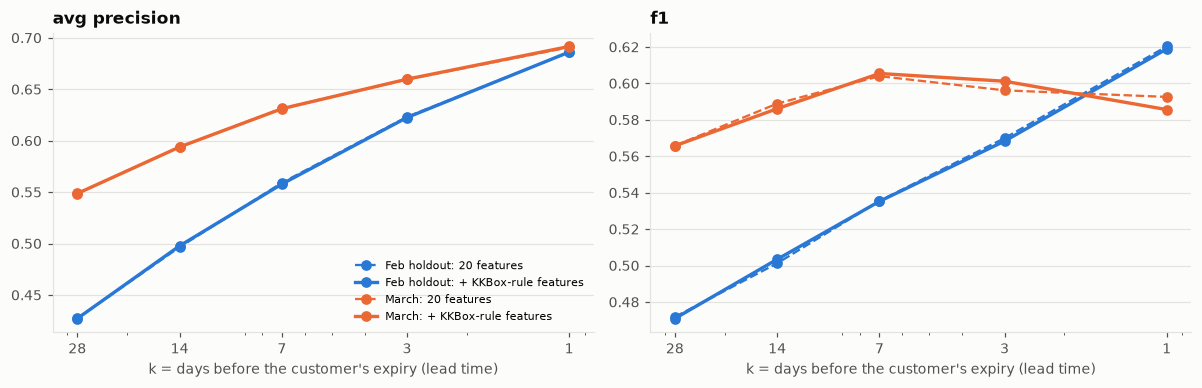

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric in zip(axes, ["avg_precision", "f1"]):
    for part, color in (("tune", C.COLORS["stay"]), ("march", C.COLORS["churn"])):
        r = cmp_.loc[part]
        lab = "Feb holdout" if part == "tune" else "March"
        ax.plot(KS, [r.loc[f"k={k}", (metric, "base")] for k in KS], marker="o", color=color, linewidth=1.5,
                linestyle="--", label=f"{lab}: 20 features")
        ax.plot(KS, [r.loc[f"k={k}", (metric, "+kkbox")] for k in KS], marker="o", color=color, linewidth=2.2,
                label=f"{lab}: + KKBox-rule features")
    ax.set_xscale("log"); ax.set_xticks(KS, [str(k) for k in KS]); ax.invert_xaxis()
    ax.set_xlabel("k = days before the customer's expiry (lead time)")
    ax.set_title(metric.replace("_", " "), loc="left")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout(); C.save_fig(fig, "10_kkbox_features"); plt.show()

In [21]:
imp_p = pd.DataFrame({s: pd.Series(models_plus[s].get_booster().get_score(importance_type="total_gain")) for s in SCENARIOS})
imp_p.index = [FEATURES_PLUS[int(k[1:])] if k.startswith("f") and k[1:].isdigit() else k for k in imp_p.index]
share = imp_p / imp_p.sum()
share.loc[[c for c in KKBOX if c in share.index]].fillna(0)

,calendar,k=28,k=14,k=7,k=3,k=1
paid_ahead,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
days_early,0.0011,0.0004,0.0006,0.0022,0.0037,0.0111
ahead_plan_days,0.0000,0.0000,0.0001,0.0001,0.0002,0.0056
ahead_auto,0.0000,0.0000,0.0000,0.0013,0.0006,0.0003
n_ahead_payments,0.0000,0.0001,0.0001,0.0000,0.0000,0.0001
ahead_extension,0.0005,0.0007,0.0013,0.0046,0.0178,0.0255


### 6.2 Does the month length in `days_to_expire` hurt March? (diagnostic A)

After an early payment, `days_to_expire` = k + extension. An early monthly auto-renew charge extends the
subscription by +28 days in February and +31 in March (notebook 11, section 5). A normal auto-renewer at k = 1
therefore reads 29 in February and 32 in March, a value never seen in training, while a risky manual 30-day early
payer reads 31 in both months. Do the March auto-renewers ("Ana") pick up false positives because of it?

In [22]:
extra = pl.concat([tables[(n, s)].select("msno", "paid_ahead", "ahead_auto")
                   .with_columns(part=pl.lit("tune" if n == "February" else "march"), scenario=pl.lit(s))
                   for n in ("February", "March") for s in SCENARIOS])
dg = (common.join(extra, on=["msno", "part", "scenario"])
      .with_columns(flag=pl.col("p") >= pl.col("scenario").replace_strict(thresholds),
                    group=pl.when(pl.col("paid_ahead") == 0).then(pl.lit("not paid ahead"))
                    .when(pl.col("ahead_auto") == 1).then(pl.lit("paid ahead, auto-renew charge"))
                    .otherwise(pl.lit("paid ahead, manual payment"))))
diag = (dg.filter(pl.col("scenario").is_in(["k=7", "k=3", "k=1"]))
        .group_by("scenario", "group", "part").agg(
            n=pl.len(), churn_rate=pl.col("is_churn").mean(), mean_p=pl.col("p").mean(),
            fp_rate=(pl.col("flag") & (pl.col("is_churn") == 0)).sum() / (pl.col("is_churn") == 0).sum(),
            precision=pl.col("is_churn").filter(pl.col("flag")).mean(),
            recall=pl.col("flag").filter(pl.col("is_churn") == 1).mean())
        .sort("scenario", "group", "part", descending=[True, False, True]).to_pandas())
diag.set_index(["scenario", "group", "part"])

n  churn_rate  mean_p  \
scenario group                         part                                
k=7      not paid ahead                tune   108537      0.0536  0.0539   
                                       march  722232      0.0778  0.0562   
         paid ahead, auto-renew charge tune     1471      0.0252  0.0244   
                                       march   12262      0.0385  0.0280   
         paid ahead, manual payment    tune      230      0.6565  0.6552   
                                       march    1796      0.6843  0.6265   
k=3      not paid ahead                tune   106000      0.0512  0.0515   
                                       march  699612      0.0751  0.0533   
         paid ahead, auto-renew charge tune     3496      0.0266  0.0294   
                                       march   30466      0.0452  0.0363   
         paid ahead, manual payment    tune      742      0.6429  0.6645   
                                       march    6212      0.6376  0.6070   
k=1      not paid ahead                tune    97931      0.0486  0.0489   
                                       march  632798      0.0695  0.0507   
         paid ahead, auto-renew charge tune    10724      0.0219  0.0214   
                                       march   89216      0.0543  0.0254   
         paid ahead, manual payment    tune     1583      0.6336  0.6443   
                                       march   14276      0.6344  0.5987   

                                              fp_rate  precision  recall  
scenario group                         part                               
k=7      not paid ahead                tune    0.0336     0.4897  0.5691  
                                       march   0.0275     0.6345  0.5662  
         paid ahead, auto-renew charge tune    0.0021     0.8696  0.5405  
                                       march   0.0026     0.8218  0.3030  
         paid ahead, manual payment    tune    0.6329     0.7449  0.9669  
                                       march   0.5362     0.7921  0.9422  
k=3      not paid ahead                tune    0.0258     0.5372  0.5539  
                                       march   0.0210     0.6651  0.5148  
         paid ahead, auto-renew charge tune    0.0015     0.8148  0.2366  
                                       march   0.0014     0.8198  0.1322  
         paid ahead, manual payment    tune    0.6226     0.7368  0.9686  
                                       march   0.5749     0.7409  0.9344  
k=1      not paid ahead                tune    0.0185     0.6074  0.5593  
                                       march   0.0156     0.6978  0.4809  
         paid ahead, auto-renew charge tune    0.0006     0.8000  0.1021  
                                       march   0.0007     0.7935  0.0452  
         paid ahead, manual payment    tune    0.6655     0.7132  0.9571  
                                       march   0.6545     0.7089  0.9184

### 6.3 Where the March plateau comes from: recall, not precision

The table above shows two things:
- the March auto-renewers who paid ahead get very low scores (false-positive rate around 0.1 %), so the month length
  does no measurable harm, because the model separates them through `state` and the payment method;
- for customers who have not paid ahead, which are most of the cohort, the **mean predicted probability stays at the
  February level while the March churn rate is higher**.

The model under-predicts March, so the threshold chosen on February flags too few March customers. Precision holds
and recall drops. Section 7 tests how to move the threshold to March without March labels.

## 7. Moving the threshold to March without March labels

Four policies, applied to the same model per k (common customers):

| policy | how the March threshold is set | uses March labels? |
|---|---|---|
| February threshold | max-F1 threshold of February `tune` (sections 5–6) | no |
| same flagged share | flag the same share of customers as the February threshold flags in `tune` | no |
| EM prior shift | estimate the March churn rate from the March scores alone (EM of Saerens et al. 2002), adjust the probabilities to that prior, then apply the February threshold | no |
| oracle | max-F1 threshold on March itself | **yes**, upper bound only |

In [23]:
def em_prior(p, pi_train, iters=200, tol=1e-7):
    # Saerens, Latinne & Decaestecker (2002): new class prior from unlabelled scores
    pi = pi_train
    for _ in range(iters):
        q = adjust(p, pi_train, pi)
        if abs(q.mean() - pi) < tol:
            break
        pi = q.mean()
    return pi

def adjust(p, pi_train, pi_new):
    a, b = pi_new / pi_train, (1 - pi_new) / (1 - pi_train)
    return a * p / (a * p + b * (1 - p))

def prf(y, yhat):
    tp = (yhat & (y == 1)).sum()
    prec, rec = tp / max(yhat.sum(), 1), tp / y.sum()
    return prec, rec, 2 * prec * rec / max(prec + rec, 1e-12)

rows = []
for s in SCENARIOS:
    feb_s = tables[("February", s)].join(split_of, on="msno")
    pi_train = feb_s.filter(pl.col("eligible") & (pl.col("split") == "fit"))["is_churn"].mean()
    tu = common.filter((pl.col("part") == "tune") & (pl.col("scenario") == s))
    ma = common.filter((pl.col("part") == "march") & (pl.col("scenario") == s))
    y, p = ma["is_churn"].to_numpy(), ma["p"].to_numpy()
    thr = thresholds[s]
    share = (tu["p"].to_numpy() >= thr).mean()
    pi_hat = em_prior(p, pi_train)
    prec_c, rec_c, thr_c = precision_recall_curve(y, p)
    f1_c = 2 * prec_c * rec_c / np.clip(prec_c + rec_c, 1e-12, None)
    policies = {
        "February threshold": p >= thr,
        "same flagged share": p >= np.quantile(p, 1 - share),
        "EM prior shift": adjust(p, pi_train, pi_hat) >= thr,
        "oracle (March labels)": p >= thr_c[np.argmax(f1_c[:-1])],
    }
    for name, yhat in policies.items():
        pr, rc, f1 = prf(y, yhat)
        rows.append({"scenario": s, "policy": name, "flagged share": yhat.mean(), "precision": pr, "recall": rc, "f1": f1,
                     "train prior": pi_train, "EM prior estimate": pi_hat if name == "EM prior shift" else np.nan,
                     "true March rate": y.mean()})
thr_res = pd.DataFrame(rows)
thr_res["scenario"] = pd.Categorical(thr_res["scenario"], SCENARIOS, ordered=True)
thr_res = thr_res.sort_values(["scenario", "policy"]).set_index(["scenario", "policy"])
thr_res

flagged share  precision  recall     f1  \
scenario policy                                                           
calendar EM prior shift                0.0866     0.5397  0.5941 0.5656   
         February threshold            0.0776     0.5702  0.5629 0.5665   
         oracle (March labels)         0.0809     0.5593  0.5756 0.5673   
         same flagged share            0.0670     0.6077  0.5178 0.5591   
k=28     EM prior shift                0.0909     0.5239  0.6056 0.5618   
         February threshold            0.0792     0.5637  0.5678 0.5658   
         oracle (March labels)         0.0795     0.5629  0.5691 0.5660   
         same flagged share            0.0678     0.6025  0.5197 0.5581   
k=14     EM prior shift                0.0832     0.5731  0.6062 0.5892   
         February threshold            0.0757     0.6001  0.5781 0.5889   
         oracle (March labels)         0.0805     0.5829  0.5972 0.5900   
         same flagged share            0.0665     0.6333  0.5359 0.5806   
k=7      EM prior shift                0.0742     0.6265  0.5909 0.6082   
         February threshold            0.0703     0.6396  0.5721 0.6040   
         oracle (March labels)         0.0821     0.5991  0.6258 0.6122   
         same flagged share            0.0633     0.6642  0.5345 0.5923   
k=3      EM prior shift                0.0663     0.6613  0.5577 0.6051   
         February threshold            0.0623     0.6741  0.5344 0.5962   
         oracle (March labels)         0.0893     0.5910  0.6715 0.6287   
         same flagged share            0.0567     0.6901  0.4979 0.5785   
k=1      EM prior shift                0.0616     0.6873  0.5383 0.6037   
         February threshold            0.0575     0.7015  0.5129 0.5926   
         oracle (March labels)         0.0906     0.5988  0.6901 0.6412   
         same flagged share            0.0523     0.7227  0.4805 0.5772   

                                train prior  EM prior estimate  \
scenario policy                                                  
calendar EM prior shift              0.0557             0.0659   
         February threshold          0.0557                NaN   
         oracle (March labels)       0.0557                NaN   
         same flagged share          0.0557                NaN   
k=28     EM prior shift              0.0549             0.0670   
         February threshold          0.0549                NaN   
         oracle (March labels)       0.0549                NaN   
         same flagged share          0.0549                NaN   
k=14     EM prior shift              0.0550             0.0639   
         February threshold          0.0550                NaN   
         oracle (March labels)       0.0550                NaN   
         same flagged share          0.0550                NaN   
k=7      EM prior shift              0.0556             0.0600   
         February threshold          0.0556                NaN   
         oracle (March labels)       0.0556                NaN   
         same flagged share          0.0556                NaN   
k=3      EM prior shift              0.0556             0.0598   
         February threshold          0.0556                NaN   
         oracle (March labels)       0.0556                NaN   
         same flagged share          0.0556                NaN   
k=1      EM prior shift              0.0557             0.0613   
         February threshold          0.0557                NaN   
         oracle (March labels)       0.0557                NaN   
         same flagged share          0.0557                NaN   

                                true March rate  
scenario policy                                  
calendar EM prior shift                  0.0786  
         February threshold              0.0786  
         oracle (March labels)           0.0786  
         same flagged share              0.0786  
k=28     EM prior shift                  0.0786  
         Febru

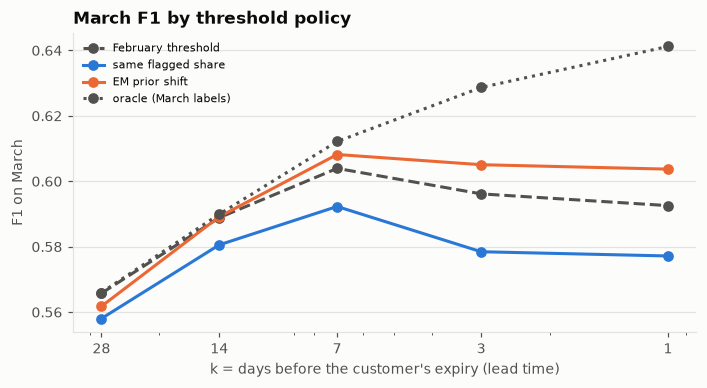

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
styles = {"February threshold": (C.COLORS["base"], "--"), "same flagged share": (C.COLORS["stay"], "-"),
          "EM prior shift": (C.COLORS["churn"], "-"), "oracle (March labels)": (C.COLORS["muted"], ":")}
for name, (color, ls) in styles.items():
    ax.plot(KS, [thr_res.loc[(f"k={k}", name), "f1"] for k in KS], marker="o", color=color, linestyle=ls, linewidth=2, label=name)
ax.set_xscale("log"); ax.set_xticks(KS, [str(k) for k in KS]); ax.invert_xaxis()
ax.set_xlabel("k = days before the customer's expiry (lead time)"); ax.set_ylabel("F1 on March")
ax.set_title("March F1 by threshold policy", loc="left"); ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); C.save_fig(fig, "10_threshold_transfer"); plt.show()

## 8. Conclusion

**Scoring each customer k days before their own expiry beats the calendar cutoff as soon as k ≤ 14, and the gain grows steadily as k shrinks.** Same customers, same 20 features, same XGBoost:

| k | AP Feb holdout | AP March | ΔAP vs calendar (Feb / March, 95 % CI excludes 0) | F1 Feb / March |
|---|---|---|---|---|
| calendar | 0.452 | 0.554 | — | 0.48 / 0.57 |
| 28 | 0.427 | 0.549 | −0.025 / −0.006 | 0.47 / 0.57 |
| 14 | 0.497 | 0.594 | +0.045 / +0.040 | 0.50 / 0.59 |
| 7 | 0.559 | 0.631 | +0.107 / +0.077 | 0.54 / 0.60 |
| 3 | 0.623 | 0.660 | +0.171 / +0.106 | 0.57 / 0.60 |
| 1 | 0.686 | 0.691 | +0.235 / +0.137 | 0.62 / 0.59 |

- **Why k = 28 loses.** The calendar cutoff already has a lead time of 1–28 days (about 15 on average). With k = 28 every customer is scored with less information than that.
- **Where the gain comes from: auto-renew churners.** At the calendar cutoff the model finds 1–6 % of them. At k = 7 it finds 22–28 %, and at k = 1, 38–44 %, with a precision of 0.83–0.90. Between the cutoff and the expiry many of them switch off auto-renew: the share of churners whose state at `as_of` is `cancel` rises from 3–4 % to 13–17 %. For manual payers the trade is the opposite: precision rises and recall falls a little. As k shrinks, listening recency (`days_since_last_log`) gains weight and the payment method loses it.
- **Part of this is detection, not prediction.** A customer who has already switched off auto-renew is easy to flag. It is still actionable, because there are k days left to make a retention offer before the subscription ends. That is the business question k encodes.
- **The F1 threshold does not travel well.** On March, F1 peaks at k = 7 (0.60) and then flattens even though AP keeps rising. The threshold is chosen on February (5.4 % churn in scope) and applied to March (7.9 %). This is the calibration problem already seen in notebook 09.
- **Not comparable with notebook 09 in absolute terms.** This population excludes the 11 % of customers who are lapsed, prepaid through March or later, or have no transactions. Those are easy cases (churn 13 %, mostly obvious), so the F1 here (0.48 in February for the calendar cutoff) is lower than the 0.58 of the whole cohort. Only the differences inside this notebook are meaningful.
- **Eligibility is almost complete.** At least 99.9 % of customers are eligible at every k, except March k = 28 (85 %). For many March customers, anchor − 28 falls before their last February renewal. They are excluded from the common comparison.

**E3c · Features for the KKBox label rule (section 6): no gain.** Adding the six features that describe a payment
made before the expiry changes AP by −0.001 to +0.002 at every k, on both holdouts. The paired-bootstrap intervals
are of the same size as the run-to-run variation of multithreaded XGBoost (about ±0.0005 AP between identical
runs). The six features take under 5 % of the total gain, even at k = 1. The reason is that the base model already
has the information:
- `days_to_expire` at `as_of` is k + the extension of the early payment;
- the last-payment block (`plan_band`, `state`, `pm_group`) describes that same payment.

Inside the customers who paid ahead before `as_of`, the base model already reaches AP 0.85 (March) to 0.91
(February) at k = 7. So the label quirk found in notebook 11 is already learned when the payment is visible, and the
March F1 plateau does not come from it.

The 26–30-day early payers that looked different in February (6 % churn) and March (42 %) are a composition
effect of month lengths (notebook 11, section 5). **Diagnostic A (6.2)** confirms that the month length hidden in
`days_to_expire` does no measurable harm: March auto-renewers who paid ahead get a false-positive rate of 0.07–0.26 %,
like February.

**The March F1 plateau is a threshold problem (sections 6.3 and 7).**
- **The model under-predicts March.** Customers who have not paid ahead churn 7.0–7.8 % in March, while their mean
  predicted probability is 5.1–5.6 %. In February the two match.
- **With the best March threshold (oracle), there is no plateau.** March F1 rises steadily as k shrinks:
  0.567 (calendar), 0.612 (k = 7), 0.629 (k = 3), 0.641 (k = 1).
- **The February threshold loses** 0.008 at k = 7, 0.033 at k = 3 and 0.049 at k = 1.
- **The label-free EM prior correction recovers part of the gap** (+0.004, +0.009 and +0.011 at k = 7, 3, 1) and is
  never worse. It only goes part of the way because it estimates the March churn rate at 6.0–6.7 % against the real
  7.9 %. The shift is not a pure prior shift: auto-renewers who paid ahead churn 5.4 % in March against 2.2 % in
  February at k = 1, and the model predicts 2.5 %.
- **Flagging the same share of customers as in February** is worse at every k.

**Recommendation.** Use the per-customer setting `as_of = expiry − k` for w1 and w2, with **k = 7** as the default. It gives +0.08 to +0.11 AP over the calendar cutoff and still leaves a week to act. The choice of k is a business decision, and the curve above is the menu. The 11 % out of scope keep the calendar model.

Before thresholding, apply the EM prior correction: it needs no labels from the new month and was never worse here. When a month's labels mature, recalibrate on it, because that is the only way to close the rest of the gap (up to +0.05 F1 at k = 1). In a real campaign the cut-off is usually set by the contact budget (top N customers). The oracle curve shows what a well-placed cut-off can reach.

In [25]:
C.write_decisions("10", "Per-cycle prediction (as-of = expiry - k)", [
    {"finding": "Scoring k days before each customer's expiry beats the calendar cutoff from k <= 14: AP +0.04 (k=14), +0.08-0.11 (k=7), +0.14-0.24 (k=1), CIs exclude 0 (Feb holdout and March)",
     "decision": "Adopt as_of = expiry - k per customer for w1 and w2 (default k = 7; final k is a business choice); calendar cutoff only for the 11 % out of scope", "kind": "open"},
    {"finding": "k = 28 is slightly worse than the calendar cutoff (-0.025 / -0.006 AP): the calendar lead time is already 1-28 days",
     "decision": "Do not use k > 14; report the AP-vs-k curve (figures/10_k_curve.png) as the lead-time menu", "kind": "no action"},
    {"finding": "The gain comes from auto-renew churners who switch off auto-renew between the cutoff and the expiry (recall 1-6 % -> 22-28 % at k=7, precision 0.83-0.90)",
     "decision": "w1/w2 data processing take a per-customer as_of (`_common` helpers accept an `as_of` column; tested equal to the global cutoff)", "kind": "transformation"},
    {"finding": "Everyone in scope expires in the label month, so expiry_month is constant",
     "decision": "In the per-cycle setting replace expiry_month by numeric days_to_expire at as_of", "kind": "transformation"},
    {"finding": "Eligibility (expiry known at as_of) >= 99.9 % except March k=28 (85 %); no record on or after the expiry is used",
     "decision": "Keep the eligibility rule and the leakage assertion in the pipeline", "kind": "cleaning"},
    {"finding": "E3c: six features describing a payment made before the expiry (paid_ahead, days_early, plan days, auto, count, extension) change AP by -0.001..+0.002 at every k; days_to_expire and the last-payment block already carry them",
     "decision": "Do not add them; the KKBox early-payment rule (nb 11) is already learned by the 20-feature model when the payment is visible at as_of", "kind": "drop"},
    {"finding": "Early payers extending 26-30 days churn 6 % (Feb) vs 42 % (Mar): composition of month lengths (nb 11 s5); March auto-renew early payers get a 0.07-0.26 % FP rate, like February (diagnostic A)",
     "decision": "Keep days_to_expire; no calendar-robust encoding needed", "kind": "no action"},
    {"finding": "March F1 plateau is a threshold problem: the model under-predicts March (7.0-7.8 % churn vs 5.1-5.6 % mean p); with the oracle March threshold F1 rises to 0.612 / 0.629 / 0.641 at k = 7 / 3 / 1, the Feb threshold loses 0.008 / 0.033 / 0.049",
     "decision": "Apply the EM prior correction (Saerens 2002) before thresholding: label-free, +0.004 / +0.009 / +0.011 F1, never worse", "kind": "transformation"},
    {"finding": "EM estimates the March prior at 6.0-6.7 % vs 7.9 % true: the shift is not a pure prior shift (auto-renew early payers 5.4 % vs 2.2 %)",
     "decision": "Recalibrate monthly on the latest month with matured labels; in a campaign set the cut-off by contact budget", "kind": "open"},
])

,finding,decision,kind
0,"Scoring k days before each customer's expiry beats the calendar cutoff from k <= 14: AP +0.04 (k=14), +0.08-0.11 (k=7), +0.14-0.24 (k=1), CIs exclude 0 (Feb holdout and March)",Adopt as_of = expiry - k per customer for w1 and w2 (default k = 7; final k is a business choice); calendar cutoff only for the 11 % out of scope,open
1,k = 28 is slightly worse than the calendar cutoff (-0.025 / -0.006 AP): the calendar lead time is already 1-28 days,Do not use k > 14; report the AP-vs-k curve (figures/10_k_curve.png) as the lead-time menu,no action
2,"The gain comes from auto-renew churners who switch off auto-renew between the cutoff and the expiry (recall 1-6 % -> 22-28 % at k=7, precision 0.83-0.90)",w1/w2 data processing take a per-customer as_of (`_common` helpers accept an `as_of` column; tested equal to the global cutoff),transformation
3,"Everyone in scope expires in the label month, so expiry_month is constant",In the per-cycle setting replace expiry_month by numeric days_to_expire at as_of,transformation
4,Eligibility (expiry known at as_of) >= 99.9 % except March k=28 (85 %); no record on or after the expiry is used,Keep the eligibility rule and the leakage assertion in the pipeline,cleaning
5,"E3c: six features describing a payment made before the expiry (paid_ahead, days_early, plan days, auto, count, extension) change AP by -0.001..+0.002 at every k; days_to_expire and the last-payment block already carry them",Do not add them; the KKBox early-payment rule (nb 11) is already learned by the 20-feature model when the payment is visible at as_of,drop
6,"Early payers extending 26-30 days churn 6 % (Feb) vs 42 % (Mar): composition of month lengths (nb 11 s5); March auto-renew early payers get a 0.07-0.26 % FP rate, like February (diagnostic A)",Keep days_to_expire; no calendar-robust encoding needed,no action
7,"March F1 plateau is a threshold problem: the model under-predicts March (7.0-7.8 % churn vs 5.1-5.6 % mean p); with the oracle March threshold F1 rises to 0.612 / 0.629 / 0.641 at k = 7 / 3 / 1, the Feb threshold loses 0.008 / 0.033 / 0.049","Apply the EM prior correction (Saerens 2002) before thresholding: label-free, +0.004 / +0.009 / +0.011 F1, never worse",transformation
8,EM estimates the March prior at 6.0-6.7 % vs 7.9 % true: the shift is not a pure prior shift (auto-renew early payers 5.4 % vs 2.2 %),Recalibrate monthly on the latest month with matured labels; in a campaign set the cut-off by contact budget,open
